# Ciclos hamiltonianos y comparación FHCP

Elias de Jesus Zuñiga de Leon · Matrícula 2430085

Se usa el núcleo del equipo y se analizan 54 intentos locales. El certificado de referencia se mantiene separado de las búsquedas.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__)

Python: 3.12.14
NumPy: 2.5.5


## 1. Grafo y certificado independiente

Una solución es una permutación de todos los vértices con aristas válidas entre consecutivos y en el cierre. El costo cuenta los pares ausentes; costo cero se certifica con otro validador.

Vértices: 66 Aristas: 99
Permutación: True
Ciclo válido: True


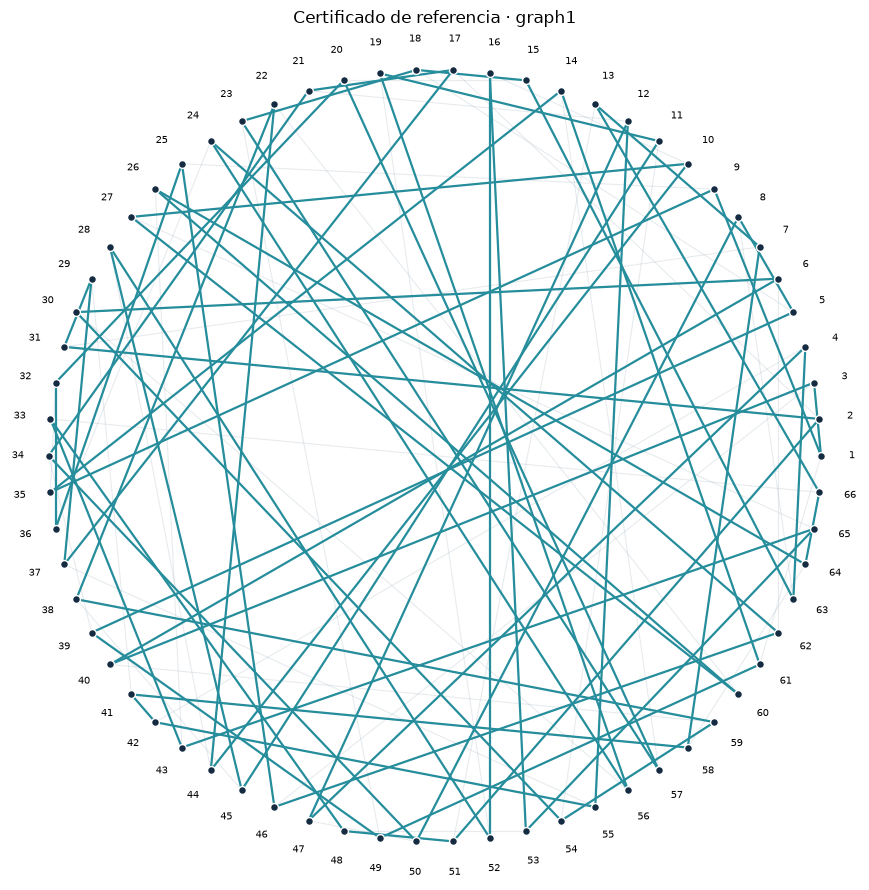

In [2]:
from ia_unidad3 import fhcp
graph, route = fhcp.reference('graph1')
print('Vértices:', graph.vertex_count(), 'Aristas:', graph.edge_count())
print('Permutación:', len(set(route)) == graph.vertex_count())
print('Ciclo válido:', fhcp.validate_cycle(graph, route).valid)
fig = plt.figure(figsize=(9, 9))
fhcp.draw_graph(fig, graph, route, 'Certificado de referencia · graph1')
plt.show()

## 2. Resultados de las seis metaheurísticas

GA, SA, ACO, ABC, DE y PSO comparten presupuesto máximo de 3,000 evaluaciones y dos segundos por intento. Se utilizaron tres grafos y tres semillas. Los tiempos dependen de esta máquina y de su carga; esta comparación pequeña no representa al conjunto de 1,001 instancias.

In [3]:
import pandas as pd
data = json.loads((ROOT/'01-fhcp-challenge/resultados/comparacion.json').read_text(encoding='utf-8'))
print(pd.DataFrame(data['resumen']).round(4).to_string(index=False))
print('Intentos:', len(data['corridas']))
print('Éxitos certificados:', sum(r['resultado']['validation']['valid'] is True for r in data['corridas']))

algoritmo                 nombre  intentos  exitos  tiempo_medio_s  costo_medio  evaluaciones_medias
       ga               Genético         9       0          1.4468       1.1111            2753.0000
       sa      Recocido simulado         9       0          0.4338       4.5556            3000.0000
       as    Colonia de hormigas         9       0          2.0000       3.6667             490.4444
      abc      Colonia de abejas         9       1          0.8862       0.8889            2874.1111
       de  Evolución diferencial         9       0          1.9530       1.1111            2209.4444
      pso Enjambre de partículas         9       0          1.9211       1.2222            2375.4444
Intentos: 54
Éxitos certificados: 1


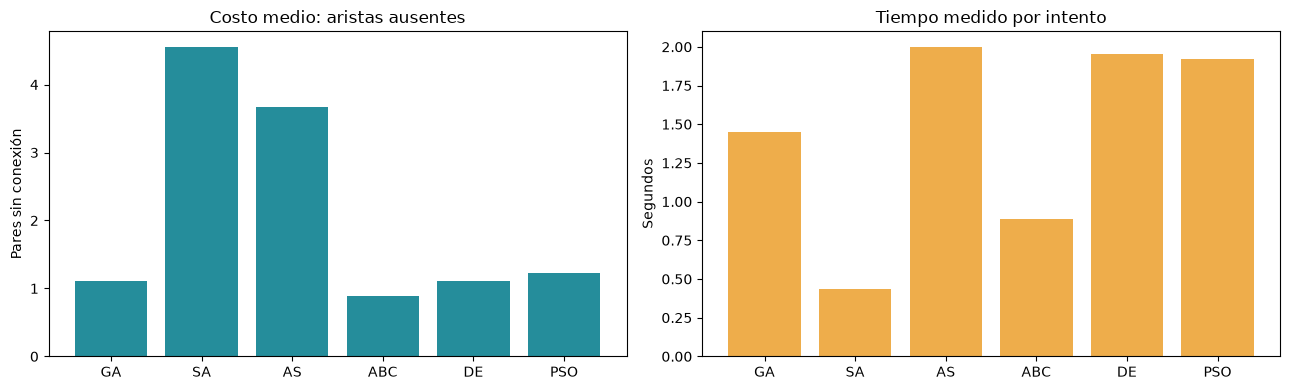

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
names = [r['algoritmo'].upper() for r in data['resumen']]
axes[0].bar(names, [r['costo_medio'] for r in data['resumen']], color='#258d9b')
axes[0].set(title='Costo medio: aristas ausentes', ylabel='Pares sin conexión')
axes[1].bar(names, [r['tiempo_medio_s'] for r in data['resumen']], color='#eead4b')
axes[1].set(title='Tiempo medido por intento', ylabel='Segundos')
plt.tight_layout(); plt.show()

## 3. Volver a comprobar el ciclo encontrado

Se verifica la ruta guardada del solver; no se sustituye por el certificado oficial.

Algoritmo: abc Instancia: graph2 Semilla: 2430087
Costo recalculado: 0
Validación independiente: True


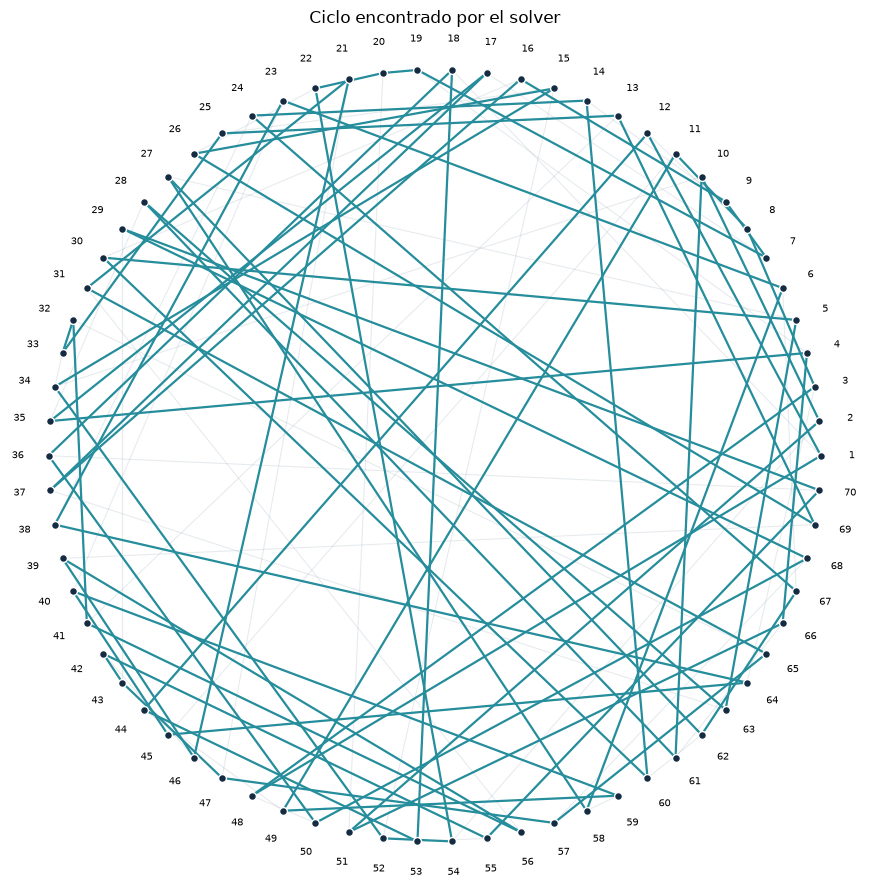

In [5]:
success = next(r for r in data['corridas'] if r['resultado']['validation']['valid'])
g = fhcp.load_graph(success['instancia'])
found = tuple(success['resultado']['best_route'])
print('Algoritmo:', success['algoritmo'], 'Instancia:', success['instancia'], 'Semilla:', success['semilla'])
print('Costo recalculado:', fhcp.evaluate_cost(g, found))
print('Validación independiente:', fhcp.validate_cycle(g, found).valid)
fig = plt.figure(figsize=(9, 9))
fhcp.draw_graph(fig, g, found, 'Ciclo encontrado por el solver')
plt.show()

## Conclusiones

Los agotamientos conservan sus mejores rutas y cuentan como intentos. Agotar un presupuesto no demuestra que un grafo carezca de ciclo. La tasa de éxito se define sobre intentos certificados; precisión, recall y F1 requieren definir casos positivos y negativos y no se usan como sustitutos de esa tasa. Los datos oficiales y sus soluciones se atribuyen a Michael Haythorpe, FHCP Challenge Set (2018).